# Edge Movement Clinic: gait-and-balance sub-score, fused elastic net + CNN (the Gait model)

**15.071 The AI Edge, Project 1.** Predicts the gait-and-balance sub-score (MDS-UPDRS Part III items 3.9-3.14, range 0-24)
of 97 people with Parkinson's disease from wearable-sensor data, with **the Gait model: late fusion of an elastic net and a
convolutional network (CNN)**.

| Part | Input | Model |
|---|---|---|
| Structured + engineered | 9 clinical inputs, 180 gait features and 30 tremor features from the sensor recordings (219 inputs) | elastic net, tuned by an inner patient-level cross-validation |
| Unstructured | raw 4 s windows (50% overlap) of the 13 IMUs and the insoles, from walking **and turning** | CNN: one shared encoder for the IMUs, one for the insoles; Huber loss; early stopping; augmentation; 3-seed ensemble |
| Fusion | the two models' predictions | simple average (nothing is fitted, so it cannot leak) |

**Evaluation:** 5-fold cross-validation repeated 10 times (50 train/test splits), split by patient: in each split 77-78
patients train and 19-20 are tested. Every scaling, standardisation, tuning and stopping decision uses the training
patients only. No MDS-UPDRS items or Hoehn & Yahr stage are inputs. `SEED = 15071`.

**Run time.** The CNN and elastic-net results are cached in `cache/`, so the notebook runs in under a minute. Without the
cache, Section 5 retrains the CNN (about 2 hours on the Apple GPU); an interrupted run resumes from the last finished fold.

## 1. Setup

In [1]:
import os
import sys

os.environ['KERAS_BACKEND'] = 'torch'   # must be set before keras is first imported

# run this notebook from the repository root (the folder that holds it)
sys.path.insert(0, os.getcwd())   # so `import edgeclinic` finds the package next to the notebook

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import torch
import keras

from edgeclinic import paths, io, targets, cv, models, evaluate, features, tremor, moving, cnn, fusion, deck_style
# figures follow the project deck's theme (colours, Georgia/Arial): edgeclinic/deck_style.py

import warnings
warnings.filterwarnings('ignore')

SEED = paths.SEED
np.random.seed(SEED)
keras.utils.set_random_seed(SEED)
paths.ensure_output_dirs()
device = 'mps (Apple GPU)' if torch.backends.mps.is_available() else 'cuda' if torch.cuda.is_available() else 'cpu'
print('Data folder found:', paths.DATA_DIR.exists())
print(f'keras {keras.__version__} on {keras.backend.backend()}, torch {torch.__version__}, device: {device}')

Data folder found: True
keras 3.15.1 on torch, torch 2.15.0, device: mps (Apple GPU)


## 2. The target and the splits

Gait-and-balance sub-score = items 3.9 (arising from chair), 3.10 (gait), 3.11 (freezing of gait), 3.12 (postural
stability), 3.13 (posture), 3.14 (body bradykinesia), each 0-4; prorated within the six items for the one patient missing
3.14. The 50 splits are by patient and balanced on the recall flag (total Part III ≥ 33).

In [2]:
analysis = targets.analysis_set(io.load_clinical('v1', 'pd'))
SUB_ITEMS = [f'MDSUPDRS_3-{k}' for k in range(9, 15)]
sub = analysis[SUB_ITEMS].astype(float)
y_sub = (sub.sum(axis=1) * len(SUB_ITEMS) / sub.notna().sum(axis=1)).to_numpy()
y_total = analysis['part3'].to_numpy()
patients = analysis['subject_id'].to_numpy()
folds = cv.repeated_folds(y_total, patients, n_splits=5, n_repeats=10, seed=paths.SEED)

print(f'{len(y_sub)} patients; sub-score mean {y_sub.mean():.2f}, SD {y_sub.std(ddof=1):.2f}, range {y_sub.min():.0f} to {y_sub.max():.0f}')
print(f'{len(folds)} train/test splits; training patients per split {min(len(f.train) for f in folds)}-{max(len(f.train) for f in folds)}, '
      f'test patients {min(len(f.test) for f in folds)}-{max(len(f.test) for f in folds)}')

97 patients; sub-score mean 4.06, SD 2.82, range 0 to 14
50 train/test splits; training patients per split 77-78, test patients 19-20


## 3. Elastic net on clinical, gait and tremor features

9 clinical inputs (age, sex, years since diagnosis, DBS, medication state and timing, height, weight), 180 gait features
(walking and turning: step regularity, stride time, arm swing, turn speed, insole timing, ...) and 30 tremor features
(3-7 Hz power while standing): 219 inputs. Inside each training fold: median imputation, clipping to the 1st-99th
percentiles, standardisation, a univariate screen to the best k inputs, and the elastic net, with k, the penalty strength
and the ridge/LASSO mix tuned by an inner 5-fold patient-level cross-validation.

In [3]:
trials = io.list_trials()
trials_v1 = trials[trials['version'] == 'v1']
pd_trials = trials_v1[trials_v1['record_id'].isin(analysis['subject_id'])]

X1 = models.clinical_features(analysis)
trial_feats = io.cached('trial_features_v1', {'code': features.code_version(), 'n': len(trials_v1)},
                        lambda: features.build_trial_features(trials_v1))
feature_cols = features.feature_columns(trial_feats)
X_sensor = (analysis[['subject_id']].merge(features.patient_features(trial_feats), left_on='subject_id',
                                           right_on='record_id', how='left')[feature_cols].set_index(analysis.index))
trem = tremor.patient_tremor(io.cached('tremor_v1', {'code': tremor.code_version(), 'n': len(pd_trials)},
                                       lambda: tremor.build(pd_trials)))
trem_cols = [c for c in trem if '__' in c]
X_trem = (analysis[['subject_id']].merge(trem, left_on='subject_id', right_on='record_id', how='left')
          [trem_cols].set_index(analysis.index))
X_best = pd.concat([X1, X_sensor, X_trem], axis=1)
cv.check_inputs(list(X_best.columns))   # no MDS-UPDRS items, Hoehn & Yahr or target-derived inputs

oof_en = cv.cached_oof(f'gt_model3_sub_{X_best.shape[1]}', models.sensor_elastic_net(), X_best, y_sub, patients, folds)
print(f'elastic net: {X1.shape[1]} clinical + {X_sensor.shape[1]} gait + {X_trem.shape[1]} tremor = {X_best.shape[1]} inputs; '
      f'out-of-fold predictions for {oof_en.patient.nunique()} patients x {oof_en.repeat.nunique()} repeats')

elastic net: 9 clinical + 180 gait + 30 tremor = 219 inputs; out-of-fold predictions for 97 patients x 10 repeats


## 4. The raw signals: 4 s Walk + Turn windows

Each window holds 400 samples (4 s at 100 Hz): for each of the 13 IMUs, acceleration and angular velocity on the sensor's
own three axes (6 channels), and from the insoles total force and centre of pressure per foot (6 channels). Walk and Turn
samples count as one movement, so windows run through walk -> turn -> walk and include the turns. A sensor counts as
present in a window when at least 90% of its samples are there; absent sensors are zeroed and flagged, so the network sees
"no information" rather than a made-up signal.

**Figure below:** one patient's self-paced walk. Each 4 s window is one arch (a rounded rectangle) of the same size, standing on the time axis
from where the window starts (dot) to where it ends. With a 50% overlap each arch starts halfway under the previous one, so
the translucent arches are darker where two windows overlap. The navy arch, the window that best straddles a walk-to-turn
change, is outlined on the signal above.

In [4]:
windows = moving.cached_windows('windows_moving_v1', pd_trials)
counts = windows['meta'].groupby('record_id').size().reindex(patients, fill_value=0)
window_table = pd.Series({'windows': counts.sum(), 'patients with windows': (counts > 0).sum(),
                          'per patient, median': counts.median(), 'per patient, min': counts.min(),
                          'per patient, max': counts.max(),
                          'shape of one window (time, sensors, channels)': str(windows['imu'].shape[1:])},
                         name='Walk + Turn').to_frame()
window_table.to_csv(paths.TABLES_DIR / 'gc_windows.csv')
window_table

,Walk + Turn
windows,2676
patients with windows,97
"per patient, median",25.0
"per patient, min",16
"per patient, max",76
"shape of one window (time, sensors, channels)","(400, 13, 6)"


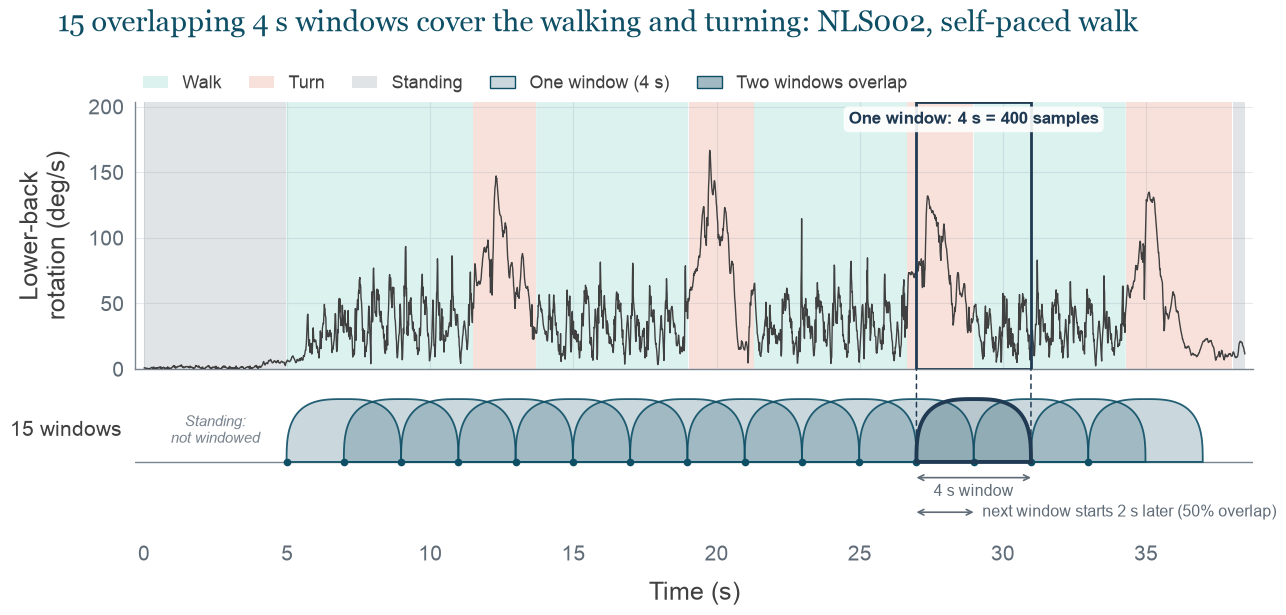

In [5]:
from matplotlib.colors import to_rgba
from matplotlib.patches import ConnectionPatch, Patch, Polygon, Rectangle


def windows_example_figure(pd_trials, windows, patient="NLS002", trial_name="SelfPace", title=True, alpha=0.22,
                           squareness=3.0):
    """One trial's lower-back rotation, shaded by activity, with its 4 s Walk + Turn windows as a row of arches.

    Each window is one arch of the same size, from where the window starts to where it ends, so all windows stay
    visible on a single row; with 50% overlap each arch starts halfway under the previous one and the translucent
    fills are darker where two windows overlap. One window is highlighted and outlined on the signal above.
    Arches are superellipse halves: squareness 2 is a semicircle; larger values flatten the top (rounded rectangle)."""
    D = deck_style
    path = pd_trials[(pd_trials.record_id == patient) & (pd_trials.trial == trial_name)]["path"].iloc[0]
    trial = io.load_trial(path, ["GeneralEvent", "LowerBack_Gyr_X", "LowerBack_Gyr_Y", "LowerBack_Gyr_Z"])
    t = trial["Time"].to_numpy()
    gyr = np.degrees(np.sqrt(trial[["LowerBack_Gyr_X", "LowerBack_Gyr_Y", "LowerBack_Gyr_Z"]].pow(2).sum(axis=1)))
    m = windows["meta"]
    starts = np.sort(m[(m.record_id == patient) & (m.trial == trial_name)]["start"].to_numpy() / paths.FS)
    win = windows["imu"].shape[1] / paths.FS
    step = float(np.median(np.diff(starts)))
    event = trial["GeneralEvent"].to_numpy()

    # highlight the window that best straddles walking and turning (turn share closest to one half)
    turn_share = [np.mean(event[(t >= s) & (t < s + win)] == "Turn") for s in starts]
    k = int(np.argmin(np.abs(np.array(turn_share) - 0.5)))
    hs = starts[k]

    fig, (ax, row) = plt.subplots(2, 1, figsize=(13.0, 6.0 if title else 5.5), sharex=True,
                                  gridspec_kw={"height_ratios": [2.4, 1.3]})
    top = gyr.max() * 1.22
    for label, colour in D.EVENT_COLORS.items():
        ax.fill_between(t, 0, top, where=(event == label), color=colour, alpha=0.22, linewidth=0)
    ax.plot(t, gyr, color=D.TEXT, linewidth=1.0, zorder=3)
    ax.set_ylim(0, top)
    ax.set_ylabel("Lower-back\nrotation (deg/s)")
    ax.add_patch(Rectangle((hs, 0), win, top, fill=False, edgecolor=D.NAVY, linewidth=2.0, zorder=4))
    ax.text(hs + win / 2, top * 0.965, f"One window: {win:g} s = {windows['imu'].shape[1]} samples",
            ha="center", va="top", fontsize=12, color=D.NAVY, fontweight="bold", zorder=5,
            bbox=dict(boxstyle="round,pad=0.3", fc=D.WHITE, ec="none", alpha=0.9))

    # one arch per window, all the same size: feet at the window's start and end
    h = 1.0
    theta = np.linspace(np.pi, 0, 200)

    def arch(s):   # half superellipse: |x/a|^n + |y/h|^n = 1, feet at the window's start and end
        c, sn = np.cos(theta), np.sin(theta)
        e = 2 / squareness
        return np.column_stack([s + win / 2 + (win / 2) * np.sign(c) * np.abs(c) ** e, h * np.abs(sn) ** e])

    for s in starts:
        row.add_patch(Polygon(arch(s), closed=True, facecolor=to_rgba(D.DARK_TEAL, alpha),
                              edgecolor=to_rgba(D.DARK_TEAL, 0.9), linewidth=1.3, zorder=2))
    row.add_patch(Polygon(arch(hs), closed=True, facecolor=to_rgba(D.NAVY, 0.10), edgecolor=D.NAVY,
                          linewidth=2.8, zorder=4))
    row.axhline(0, color=D.GREY, linewidth=1.0, zorder=1)
    row.plot(starts, np.zeros_like(starts), "o", markersize=4.5, color=D.DARK_TEAL, zorder=3)   # window starts
    for x in (hs, hs + win):   # connect the highlighted arch's feet to the same window on the signal
        fig.add_artist(ConnectionPatch((x, 0), (x, 0), coordsA="data", coordsB="data", axesA=row, axesB=ax,
                                       color=D.NAVY, linewidth=1.1, linestyle=(0, (3, 3)), zorder=1))

    def dim(x1, x2, y, text):
        row.annotate("", (x2, y), (x1, y), arrowprops=dict(arrowstyle="<->", color=D.TEXT_2, lw=1.2,
                                                           shrinkA=0, shrinkB=0))
        wide = x2 - x1 > 3
        row.text((x1 + x2) / 2 if wide else x2 + 0.3, y - 0.10 if wide else y, text, ha="center" if wide else "left",
                 va="top" if wide else "center", fontsize=11.5, color=D.TEXT_2)
    dim(hs, hs + win, -0.25, f"{win:g} s window")
    dim(hs, hs + step, -0.80, f"next window starts {step:g} s later ({1 - step / win:.0%} overlap)")

    if starts.min() > t.min() + 1:
        row.text((t.min() + starts.min()) / 2, h / 2, "Standing:\nnot windowed", ha="center", va="center",
                 fontsize=11, color=D.GREY, style="italic")
    row.set_ylim(-1.15, 1.15)
    row.set_yticks([]); row.grid(False)
    row.spines["left"].set_visible(False); row.spines["bottom"].set_visible(False)
    row.tick_params(axis="x", length=0)
    row.set_ylabel(f"{len(starts)} windows", rotation=0, ha="right", va="center", fontsize=15)
    row.yaxis.set_label_coords(-0.012, (h / 2 + 1.15) / 2.3)
    row.set_xlabel("Time (s)")
    row.set_xlim(t.min() - 0.3, t.max() + 0.3)

    c = np.array(to_rgba(D.DARK_TEAL)[:3])
    one = alpha * c + (1 - alpha)
    two = alpha * c + (1 - alpha) * one
    handles = [Patch(facecolor=col, alpha=0.22, label=l) for l, col in D.EVENT_COLORS.items()]
    handles += [Patch(facecolor=tuple(one), edgecolor=D.DARK_TEAL, label=f"One window ({win:g} s)"),
                Patch(facecolor=tuple(two), edgecolor=D.DARK_TEAL, label="Two windows overlap")]
    ax.legend(handles=handles, loc="lower left", bbox_to_anchor=(0, 1.01), ncol=5, handlelength=1.4,
              columnspacing=1.5, borderaxespad=0)
    if title:
        D.title_block(fig, f"{len(starts)} overlapping {win:g} s windows cover the walking and turning: "
                           f"{patient}, self-paced walk", x=0.06, top=0.985)
        fig.subplots_adjust(left=0.12, right=0.98, bottom=0.11, top=0.83, hspace=0.10)
    else:
        fig.subplots_adjust(left=0.12, right=0.98, bottom=0.12, top=0.92, hspace=0.10)
    return fig


with deck_style.context():
    fig = windows_example_figure(pd_trials, windows, title=True)
    deck_style.save(fig, 'gc_windows_example')
    slide = windows_example_figure(pd_trials, windows, title=False)   # no title: the slide carries it
    deck_style.save(slide, 'gc_windows_example_slide')
    plt.close(slide)
    plt.show()

## 5. The CNN

For each of the 50 training folds, `cnn.oof_cnn` trains three networks with different seeds and averages them. Inside each
fold: channel standardisation from the training windows only; the target standardised with the training patients' mean
and SD; one sixth of the training *patients* held out to choose the stopping epoch (at most 100, patience 10); augmentation
by small random sensor rotations, amplitude scaling and noise. A patient's prediction is the mean over their windows and the
three seeds, so every test patient is predicted by networks that never saw them.

Each finished fold is saved to `cache/oof_cnn_gait_moving_*`, so this cell is fast when the cache exists and resumes if
interrupted.

In [6]:
SEEDS = (paths.SEED, paths.SEED + 1, paths.SEED + 2)
oof_cnn = cnn.oof_cnn('oof_cnn_gait_moving', windows, y_sub, patients, folds, seeds=SEEDS)
oof_cnn.drop_duplicates(['repeat', 'fold'])['epochs'].describe()[['50%', 'min', 'max']].rename(
    {'50%': 'median'}).rename('stopping epoch (mean of 3 seeds)').round(0).to_frame()

,stopping epoch (mean of 3 seeds)
median,18.0
min,4.0
max,63.0


### The network

The diagram is drawn from the model itself (`cnn.build_cnn` with the size and dropout used in every fold), so the shapes and
parameter counts below are the trained network's. Each 4 s window holds 400 samples from 13 IMUs (6 channels each:
3-axis acceleration and angular velocity) and the two insoles (6 channels). **One encoder is shared by all 13 IMUs**: each
sensor's signal goes through the same three convolution layers, so the 97 patients train one encoder rather than 13, and
the 13 sensor summaries are kept in a fixed order so the head knows which body segment each came from. The insoles get
their own encoder. A missing sensor's summary is multiplied by 0. A small dense head turns the 448 numbers into one score
per window; a patient's CNN prediction is the mean over their windows and the 3 seeds.

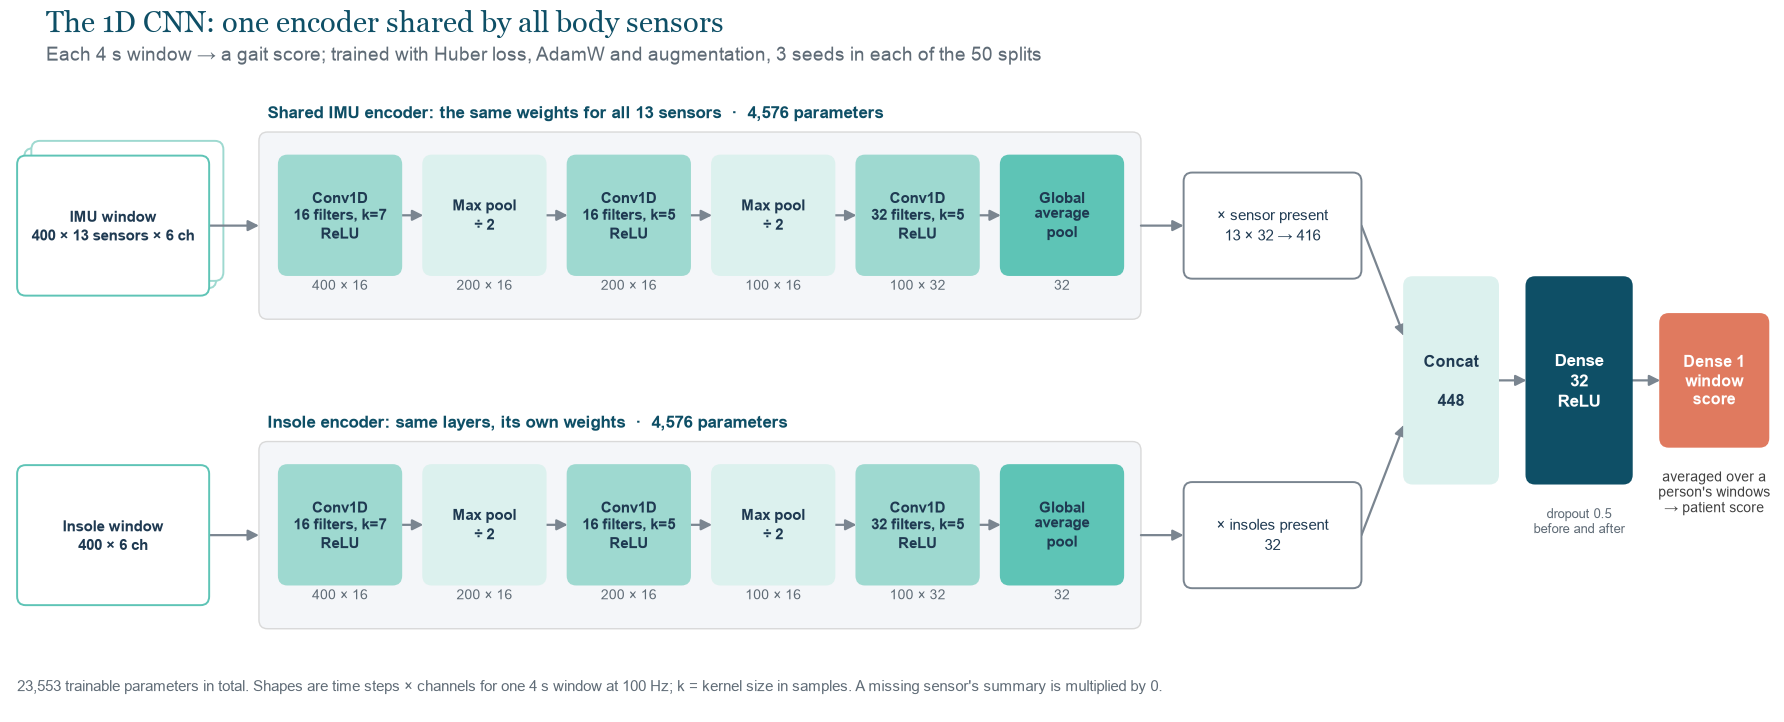

In [7]:
import inspect
from matplotlib.patches import FancyBboxPatch, Rectangle

# the network exactly as trained in every fold: cnn.fit_predict's defaults for size and dropout
FIT_DEFAULTS = {k: v.default for k, v in inspect.signature(cnn.fit_predict).parameters.items()
                if v.default is not inspect.Parameter.empty}
gait_net = cnn.build_cnn(window=windows["imu"].shape[1], n_sensors=windows["imu"].shape[2],
                         n_channels=windows["imu"].shape[3], n_insole=windows["insole"].shape[2],
                         filters=FIT_DEFAULTS["filters"], dropout=FIT_DEFAULTS["dropout"])


def cnn_architecture_figure(model, dropout, title=True):
    """Deck-style diagram of the gait CNN; every shape and parameter count is read from `model`."""
    D = deck_style
    td = next(l for l in model.layers if l.__class__.__name__ == "TimeDistributed")
    imu_enc, ins_enc = td.layer, model.get_layer("insole_encoder")
    dense = [l for l in model.layers if l.__class__.__name__ == "Dense"]
    n_sensors, window, n_ch = model.get_layer("imu").output.shape[2], model.get_layer("imu").output.shape[1], model.get_layer("imu").output.shape[3]
    n_ins = model.get_layer("insole").output.shape[2]
    z = imu_enc.layers[-1].output.shape[-1]
    concat = model.get_layer("concatenate").output.shape[-1]

    def chip(layer):
        k, out = layer.__class__.__name__, layer.output.shape
        if k == "Conv1D":
            return f"Conv1D\n{layer.filters} filters, k={layer.kernel_size[0]}\nReLU", f"{out[1]} × {out[2]}", D.LIGHT_TEAL
        if k == "MaxPooling1D":
            return "Max pool\n÷ 2", f"{out[1]} × {out[2]}", D.MINT
        return "Global\naverage\npool", f"{out[1]}", D.TEAL

    fig, ax = plt.subplots(figsize=(18, 7.2 if title else 6.2))
    ax.set_xlim(0, 124); ax.set_ylim(0, 42.5); ax.axis("off")

    def box(x, y, w, h, text, fc, ec=None, tc=D.NAVY, fs=11.5, bold=True, lw=1.4, style="round,pad=0,rounding_size=0.6", z=3):
        ax.add_patch(FancyBboxPatch((x, y), w, h, boxstyle=style, fc=fc, ec=ec or fc, lw=lw, zorder=z))
        if text:
            ax.text(x + w / 2, y + h / 2, text, ha="center", va="center", fontsize=fs, color=tc,
                    fontweight="bold" if bold else "normal", linespacing=1.3, zorder=z + 1)

    def arrow(x1, y1, x2, y2):
        ax.annotate("", (x2, y2), (x1, y1), zorder=2,
                    arrowprops=dict(arrowstyle="-|>", color=D.GREY, lw=1.6, mutation_scale=16, shrinkA=0, shrinkB=0))

    rows = [  # (centre y, input label, encoder, encoder title, gate label)
        (33, f"IMU window\n{window} × {n_sensors} sensors × {n_ch} ch", imu_enc,
         f"Shared IMU encoder: the same weights for all {n_sensors} sensors  ·  {imu_enc.count_params():,} parameters",
         f"× sensor present\n{n_sensors} × {z} → {n_sensors * z}"),
        (12, f"Insole window\n{window} × {n_ins} ch", ins_enc,
         f"Insole encoder: same layers, its own weights  ·  {ins_enc.count_params():,} parameters",
         f"× insoles present\n{z}"),
    ]
    h = 9.5
    for k, (cy, label, enc, enc_title, gate) in enumerate(rows):
        if k == 0:   # a stack behind the IMU input: 13 sensors through one encoder
            for d in (1.0, 0.5):
                box(0.5 + d, cy - h / 2 + d, 13.5, h, "", D.WHITE, D.LIGHT_TEAL, z=1 + d)
        box(0.5, cy - h / 2, 13.5, h, label, D.WHITE, D.TEAL, fs=11, z=3)
        gx, gw = 17.5, 62
        box(gx, cy - h / 2 - 1.6, gw, h + 3.2, "", D.CARD, D.RULE, lw=1.0, z=1)
        ax.text(gx + 0.6, cy + h / 2 + 2.3, enc_title, fontsize=12, color=D.DARK_TEAL, fontweight="bold", va="bottom")
        arrow(14.0, cy, gx, cy)
        layers_ = enc.layers
        cw, gap = 8.6, 1.55
        x = gx + 1.4
        for j, layer in enumerate(layers_):
            name, shape_, fc = chip(layer)
            box(x, cy - h / 2 + 1.4, cw, h - 1.4, name, fc, fs=10.5, tc=D.NAVY if fc != D.TEAL else D.NAVY)
            ax.text(x + cw / 2, cy - h / 2 + 0.2, shape_, ha="center", va="bottom", fontsize=10, color=D.TEXT_2, zorder=5)
            if j < len(layers_) - 1:
                arrow(x + cw, cy + 0.7, x + cw + gap, cy + 0.7)
            x += cw + gap
        arrow(gx + gw, cy, 82.5, cy)
        box(82.5, cy - 3.6, 12.5, 7.2, gate, D.WHITE, D.GREY, fs=11, bold=False)
        arrow(95.0, cy, 98.0, 22.5 + (3.0 if k == 0 else -3.0))

    box(98.0, 15.5, 6.6, 14, f"Concat\n\n{concat}", D.MINT, fs=11.5)
    arrow(104.6, 22.5, 106.6, 22.5)
    box(106.6, 15.5, 7.4, 14, f"Dense\n{dense[0].units}\nReLU", D.DARK_TEAL, tc=D.WHITE, fs=12)
    ax.text(110.3, 13.9, f"dropout {dropout:g}\nbefore and after", ha="center", va="top", fontsize=9.5, color=D.TEXT_2)
    arrow(114.0, 22.5, 116.0, 22.5)
    box(116.0, 18.0, 7.6, 9.0, f"Dense {dense[1].units}\nwindow\nscore", D.CORAL, tc=D.WHITE, fs=11.5)
    ax.text(119.8, 16.4, "averaged over a\nperson's windows\n→ patient score", ha="center", va="top", fontsize=10, color=D.TEXT)

    ax.text(0.5, 1.2, f"{model.count_params():,} trainable parameters in total. Shapes are time steps × channels for one "
            f"{window / 100:g} s window at 100 Hz; k = kernel size in samples. A missing sensor's summary is multiplied by 0.",
            fontsize=11, color=D.TEXT_2, va="bottom")
    if title:
        D.title_block(fig, "The 1D CNN: one encoder shared by all body sensors",
                      f"Each 4 s window → a gait score; trained with Huber loss, AdamW and augmentation, "
                      f"3 seeds in each of the 50 splits", x=0.03, top=0.985)
        fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.88)
    else:
        fig.subplots_adjust(left=0.01, right=0.99, bottom=0.01, top=0.99)
    return fig


with deck_style.context():
    fig = cnn_architecture_figure(gait_net, FIT_DEFAULTS["dropout"], title=True)
    deck_style.save(fig, "gc_cnn_architecture")
    slide = cnn_architecture_figure(gait_net, FIT_DEFAULTS["dropout"], title=False)
    deck_style.save(slide, "gc_cnn_architecture_slide")
    plt.close(slide)
    plt.show()

In [8]:
gait_net.summary(line_length=100)
print()
gait_net.get_layer('time_distributed').layer.summary(line_length=100)

Model: "gait_cnn"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                ┃ Output Shape            ┃        Param # ┃ Connected to            ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━┩
│ imu (InputLayer)            │ (None, 400, 13, 6)      │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ present (InputLayer)        │ (None, 14)              │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ permute (Permute)           │ (None, 13, 400, 6)      │              0 │ imu[0][0]               │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ get_item (GetItem)          │ (None, 13)              │              0 │ present[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ time_distributed            │ (None, 13, 32)          │          4,576 │ permute[0][0]           │
│ (TimeDistributed)           │                         │                │                         │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ reshape (Reshape)           │ (None, 13, 1)           │              0 │ get_item[0][0]          │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ insole (InputLayer)         │ (None, 400, 6)          │              0 │ -                       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ multiply (Multiply)         │ (None, 13, 32)          │              0 │ time_distributed[0][0], │
│                             │                         │                │ reshape[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ insole_encoder (Sequential) │ (None, 32)              │          4,576 │ insole[0][0]            │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ get_item_1 (GetItem)        │ (None, 1)               │              0 │ present[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ flatten (Flatten)           │ (None, 416)             │              0 │ multiply[0][0]          │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ multiply_1 (Multiply)       │ (None, 32)              │              0 │ insole_encoder[0][0],   │
│                             │                         │                │ get_item_1[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ concatenate (Concatenate)   │ (None, 448)             │              0 │ flatten[0][0],          │
│                             │                         │                │ multiply_1[0][0]        │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout (Dropout)           │ (None, 448)             │              0 │ concatenate[0][0]       │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dense (Dense)               │ (None, 32)              │         14,368 │ dropout[0][0]           │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dropout_1 (Dropout)         │ (None, 32)              │              0 │ dense[0][0]             │
├─────────────────────────────┼─────────────────────────┼────────────────┼─────────────────────────┤
│ dense_1 (Dense)             │ (None, 1)               │    

 Total params: 23,553 (92.00 KB)

 Trainable params: 23,553 (92.00 KB)

 Non-trainable params: 0 (0.00 B)

Model: "imu_encoder"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)                               ┃ Output Shape                    ┃           Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ conv1d (Conv1D)                            │ (None, 400, 16)                 │               688 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ max_pooling1d (MaxPooling1D)               │ (None, 200, 16)                 │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv1d_1 (Conv1D)                          │ (None, 200, 16)                 │             1,296 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ max_pooling1d_1 (MaxPooling1D)             │ (None, 100, 16)                 │                 0 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ conv1d_2 (Conv1D)                          │ (None, 100, 32)                 │             2,592 │
├────────────────────────────────────────────┼─────────────────────────────────┼───────────────────┤
│ global_average_pooling1d                   │ (None, 32)                      │                 0 │
│ (GlobalAveragePooling1D)                   │                                 │                   │
└────────────────────────────────────────────┴─────────────────────────────────┴───────────────────┘

 Total params: 4,576 (17.88 KB)

 Trainable params: 4,576 (17.88 KB)

 Non-trainable params: 0 (0.00 B)

**The same network as a block diagram.** Each block is one layer's output: in the encoder its height grows with the number of time
steps (400 → 200 → 100 as max pooling halves time) and its thickness with the number of channels (16 → 32); after pooling, height shows the vector's
length. The 13 sensor summaries (13 × 32) are flattened to 416 and joined with the insoles' 32 to give 448; each
summary, including the insoles', is multiplied by whether that sensor was present. The input
is a real 4 s window from the lower-back sensor (top three traces acceleration, bottom three angular velocity); the same
encoder reads each of the 13 IMUs, and the insoles have their own encoder. The network predicts on a standardised scale, rescaled to sub-score points with the training
patients' mean and SD. The window score then follows the panel on
the right: averaged over the patient's windows and the 3 seeds, averaged with the elastic net, and compared with the
clinic cut-off. Shapes and parameter counts are read from the model.

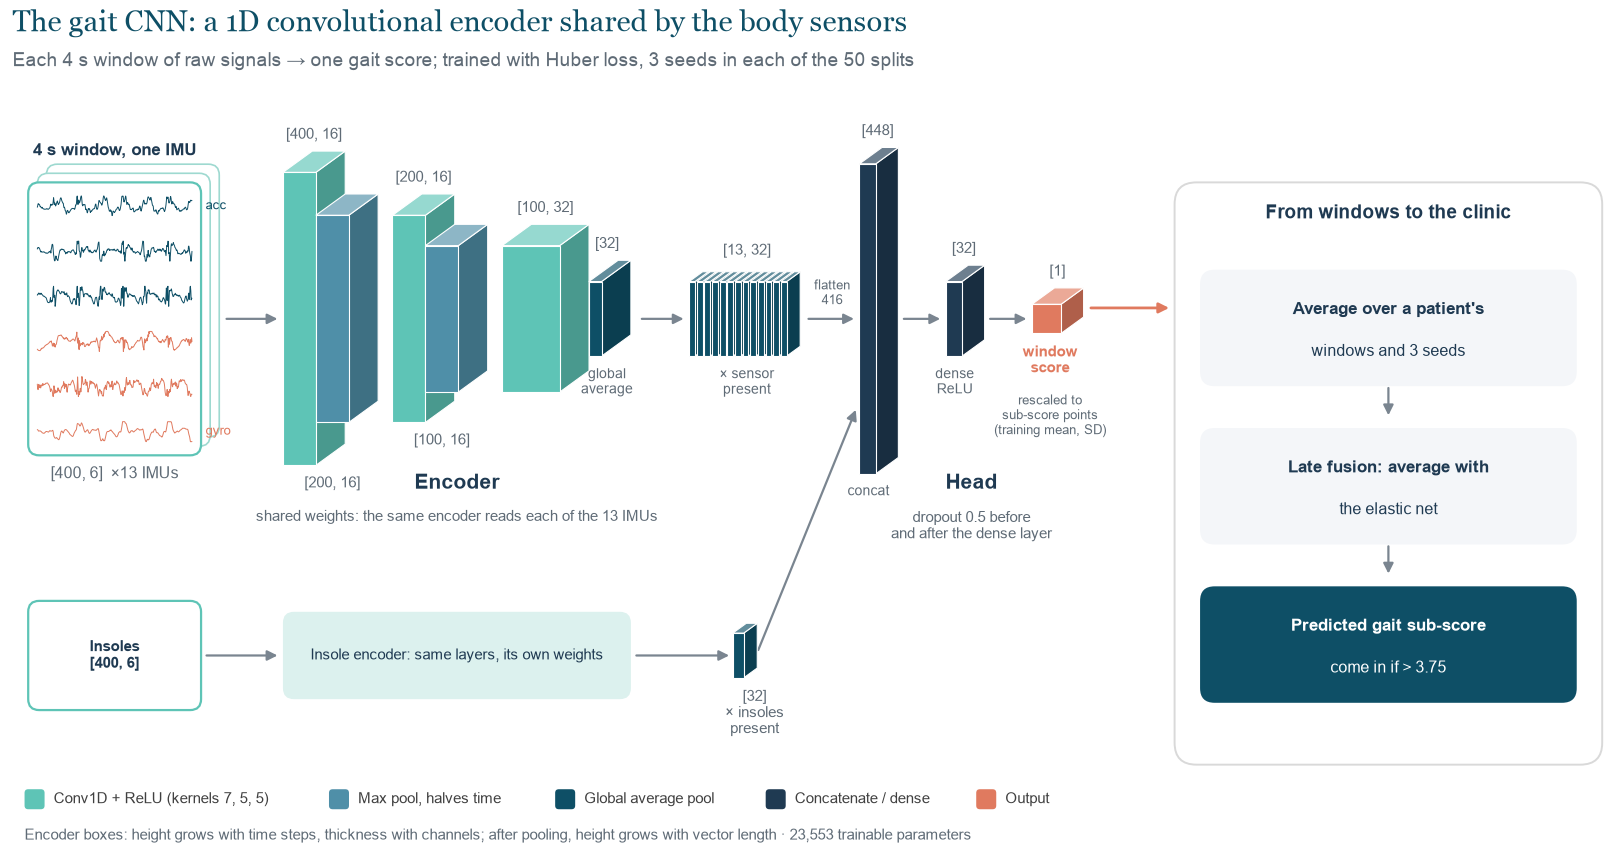

In [9]:
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch, Polygon
from matplotlib.colors import to_rgb


def cnn_blocks_figure(model, windows, title=True, patient="NLS002"):
    """3-D block diagram of the gait CNN (box height ~ time steps, thickness ~ channels); shapes read from `model`."""
    D = deck_style
    td = next(l for l in model.layers if l.__class__.__name__ == "TimeDistributed")
    enc, ins_enc = td.layer, model.get_layer("insole_encoder")
    n_sensors = model.get_layer("imu").output.shape[2]
    T, n_ch = model.get_layer("imu").output.shape[1], model.get_layer("imu").output.shape[3]
    z = enc.layers[-1].output.shape[-1]
    concat = model.get_layer("concatenate").output.shape[-1]
    dense = [l for l in model.layers if l.__class__.__name__ == "Dense"]

    fig, ax = plt.subplots(figsize=(17, 8.6 if title else 7.7))
    ax.set_aspect("equal"); ax.axis("off")

    def shade(c, f):   # lighten (f > 0) or darken (f < 0) a colour
        r = np.array(to_rgb(c))
        return tuple(r + (1 - r) * f) if f > 0 else tuple(r * (1 + f))

    def cuboid(x, yc, w, h, c, d=2.6, z_=3):
        """Front face w x h centred on yc, receding up and to the right by d."""
        dx, dy = 0.62 * d, 0.45 * d
        y = yc - h / 2
        front = [(x, y), (x + w, y), (x + w, y + h), (x, y + h)]
        top = [(x, y + h), (x + w, y + h), (x + w + dx, y + h + dy), (x + dx, y + h + dy)]
        side = [(x + w, y), (x + w + dx, y + dy), (x + w + dx, y + h + dy), (x + w, y + h)]
        for pts, f in ((side, -0.22), (top, 0.35), (front, 0.0)):
            ax.add_patch(Polygon(pts, closed=True, fc=shade(c, f), ec=D.WHITE, lw=0.8, zorder=z_))
        return x + w + dx, y + h + dy, y          # right edge, top edge, bottom edge

    def label(x, y, text, va="bottom", size=11, color=None, bold=False, ha="center"):
        ax.text(x, y, text, ha=ha, va=va, fontsize=size, color=color or D.TEXT_2,
                fontweight="bold" if bold else "normal", zorder=6)

    def arrow(x1, y1, x2, y2, color=None, lw=1.6, style="-|>"):
        ax.add_patch(FancyArrowPatch((x1, y1), (x2, y2), arrowstyle=style, mutation_scale=15,
                                     color=color or D.GREY, lw=lw, zorder=2, shrinkA=0, shrinkB=0))

    hgt = lambda t: 3.6 * np.sqrt(t / 20)           # box height from time steps: 400 -> 16, 100 -> 8
    thick = lambda c: 0.45 + 0.085 * c               # box thickness from channels: 16 -> 1.8, 32 -> 3.2
    Y = 27.5                                          # centre line of the IMU encoder

    # ---- input: a real window from the lower-back sensor (each channel scaled for display) ----------------
    m = windows["meta"]
    i = int(np.flatnonzero((m["record_id"] == patient).to_numpy())[len(m[m.record_id == patient]) // 2])
    s = list(paths.IMUS).index("LowerBack") if "LowerBack" in paths.IMUS else 0
    sig = windows["imu"][i, :, s, :]
    ix, iw, ih = 1.0, 9.5, 15.0
    for k_, off in enumerate((1.0, 0.5)):           # the other sensors, stacked behind
        ax.add_patch(FancyBboxPatch((ix + off, Y - ih / 2 + off), iw, ih, boxstyle="round,pad=0,rounding_size=0.6",
                                    fc=D.WHITE, ec=D.LIGHT_TEAL, lw=1.2, zorder=1 + k_))
    ax.add_patch(FancyBboxPatch((ix, Y - ih / 2), iw, ih, boxstyle="round,pad=0,rounding_size=0.6",
                                fc=D.WHITE, ec=D.TEAL, lw=1.6, zorder=3))
    tt = np.linspace(ix + 0.5, ix + iw - 0.5, sig.shape[0])
    for c in range(n_ch):
        v = sig[:, c]
        v = (v - v.mean()) / (v.std() + 1e-9)
        yc = Y + ih / 2 - 1.3 - c * (ih - 2.6) / (n_ch - 1)
        ax.plot(tt, yc + 0.55 * np.clip(v, -2.2, 2.2) / 2.2, color=(D.DARK_TEAL if c < 3 else D.CORAL), lw=0.7, zorder=4)
    label(ix + iw / 2, Y + ih / 2 + 1.3, f"4 s window, one IMU", size=12, color=D.NAVY, bold=True)
    label(ix + iw / 2, Y - ih / 2 - 0.6, f"[{T}, {n_ch}]  ×{n_sensors} IMUs", va="top", size=11.5)
    ax.text(ix + iw + 0.25, Y + ih / 2 - 1.3, "acc", fontsize=9, color=D.DARK_TEAL, va="center")
    ax.text(ix + iw + 0.25, Y - ih / 2 + 1.3, "gyro", fontsize=9, color=D.CORAL, va="center")

    # ---- encoder: conv / pool pairs, then global average pooling -------------------------------------------
    x = 15.0
    arrow(ix + iw + 1.4, Y, x - 0.3, Y)
    colours = {"Conv1D": D.TEAL, "MaxPooling1D": D.STEEL, "GlobalAveragePooling1D": D.DARK_TEAL}
    enc_x0 = x
    up = True
    for layer in enc.layers:
        kind, out = layer.__class__.__name__, layer.output.shape
        if kind == "GlobalAveragePooling1D":
            x += 1.6
            r, tp, bt = cuboid(x, Y, 0.7, hgt(out[1] * 1.0) * 0.9, colours[kind], d=2.6)
            label(x + 1.0, tp + 0.5, f"[{out[1]}]")
            label(x + 1.0, bt - 0.6, "global\naverage", va="top", size=10)
            x = r
            continue
        h, w = hgt(out[1]), thick(out[2])
        r, tp, bt = cuboid(x, Y, w, h, colours[kind])
        txt = f"[{out[1]}, {out[2]}]"
        if kind == "Conv1D":
            label(x + w / 2 + 0.8, tp + 0.5, txt)
            pair_bottom = bt
        else:   # pool: label under the pair, below the taller conv block
            label(x + w / 2, pair_bottom - 0.6, txt, va="top")
        x = x + w + (0.0 if kind == "Conv1D" else 2.4)
    enc_x1 = x
    label((enc_x0 + enc_x1) / 2, 9.4 + 9.6, "Encoder", va="top", size=15, color=D.NAVY, bold=True)
    label((enc_x0 + enc_x1) / 2, 9.4 + 7.6, f"shared weights: the same encoder reads each of the {n_sensors} IMUs",
          va="top", size=10.5)

    # ---- 13 sensor summaries x presence --------------------------------------------------------------------
    sx = enc_x1 + 3.2
    arrow(enc_x1 + 0.6, Y, sx - 0.3, Y)
    for j in range(n_sensors):
        cuboid(sx + j * 0.42, Y - j * 0.0, 0.32, hgt(z) * 0.9, D.DARK_TEAL, d=1.2, z_=3 + j * 0.01)
    sx1 = sx + n_sensors * 0.42 + 0.9
    label((sx + sx1) / 2, Y + hgt(z) * 0.45 + 1.3, f"[{n_sensors}, {z}]")
    label((sx + sx1) / 2, Y - hgt(z) * 0.45 - 0.6, "× sensor\npresent", va="top", size=10)

    # ---- insole branch (same layers, own weights) -------------------------------------------------------------
    Yi = 9.0
    ins_w = hgt(z) * 0.9
    ax.add_patch(FancyBboxPatch((ix, Yi - 3.0), iw, 6.0, boxstyle="round,pad=0,rounding_size=0.6",
                                fc=D.WHITE, ec=D.TEAL, lw=1.6, zorder=3))
    label(ix + iw / 2, Yi, f"Insoles\n[{T}, {ins_enc.layers[0].input.shape[-1]}]", va="center", size=11, color=D.NAVY, bold=True)
    ax.add_patch(FancyBboxPatch((enc_x0, Yi - 2.4), enc_x1 - enc_x0, 4.8, boxstyle="round,pad=0,rounding_size=0.6",
                                fc=D.MINT, ec="none", zorder=2))
    label((enc_x0 + enc_x1) / 2, Yi, "Insole encoder: same layers, its own weights", va="center", size=11, color=D.NAVY)
    arrow(ix + iw + 0.3, Yi, enc_x0 - 0.3, Yi)
    cuboid(sx + 2.4, Yi, 0.6, ins_w * 0.6, D.DARK_TEAL, d=1.2)
    label(sx + 3.6, Yi - ins_w * 0.3 - 0.6, f"[{z}]\n× insoles\npresent", va="top", size=10.5)
    arrow(enc_x1 + 0.3, Yi, sx + 2.2, Yi)

    # ---- head: concatenate, dense, window score ------------------------------------------------------------
    cx = sx1 + 3.0
    arrow(sx1 + 0.2, Y, cx - 0.3, Y)
    label((sx1 + cx) / 2, Y + 0.6, f"flatten\n{n_sensors * z}", size=9.5)   # 13 x 32 -> 416, then + 32 insole = 448
    arrow(sx + 3.8, Yi + 0.3, cx - 0.2, Y - 5.0)
    r, tp, bt = cuboid(cx, Y, 0.9, hgt(concat), D.NAVY, d=2.0)
    label(cx + 1.0, tp + 0.5, f"[{concat}]")
    label(cx + 0.5, bt - 0.6, "concat", va="top", size=10)
    dx_ = r + 2.6
    arrow(r + 0.3, Y, dx_ - 0.3, Y)
    r, tp, bt = cuboid(dx_, Y, 0.9, hgt(dense[0].units) * 0.9, D.NAVY, d=2.0)
    label(dx_ + 1.0, tp + 0.5, f"[{dense[0].units}]")
    label(dx_ + 0.5, bt - 0.6, "dense\nReLU", va="top", size=10)
    ox = r + 2.6
    arrow(r + 0.3, Y, ox - 0.3, Y)
    r, tp, bt = cuboid(ox, Y, 1.6, 1.6, D.CORAL, d=2.0, z_=4)
    label(ox + 1.4, tp + 0.5, f"[{dense[1].units}]")
    label(ox + 1.0, bt - 0.6, "window\nscore", va="top", size=10.5, color=D.CORAL, bold=True)
    label(ox + 1.0, bt - 3.3, "rescaled to\nsub-score points\n(training mean, SD)", va="top", size=9.5)
    label((cx + r) / 2, 9.4 + 9.6, "Head", va="top", size=15, color=D.NAVY, bold=True)
    head_right = r
    label((cx + r) / 2, 9.4 + 7.6, f"dropout {FIT_DEFAULTS['dropout']:g} before\nand after the dense layer", va="top", size=10.5)

    # ---- from window score to the clinic: the counterpart of the downstream models panel -------------------
    px0 = head_right + 5.0
    px1, py0, py1 = px0 + 23.5, 3.0, 35.0
    ax.add_patch(FancyBboxPatch((px0, py0), px1 - px0, py1 - py0, boxstyle="round,pad=0,rounding_size=1.2",
                                fc=D.WHITE, ec=D.RULE, lw=1.4, zorder=1))
    label((px0 + px1) / 2, py1 - 1.2, "From windows to the clinic", va="top", size=14, color=D.NAVY, bold=True)
    steps = [("Average over a patient's", "windows and 3 seeds", D.CARD, D.NAVY),
             ("Late fusion: average with", "the elastic net", D.CARD, D.NAVY),
             ("Predicted gait sub-score", "come in if > 3.75", D.DARK_TEAL, D.WHITE)]
    by = py1 - 4.8
    for n_, (a, b, fc, tc) in enumerate(steps):
        ax.add_patch(FancyBboxPatch((px0 + 1.4, by - 6.4), px1 - px0 - 2.8, 6.4, boxstyle="round,pad=0,rounding_size=0.8",
                                    fc=fc, ec="none", zorder=3))
        ax.text((px0 + px1) / 2, by - 2.2, a, ha="center", va="center", fontsize=12, color=tc, fontweight="bold", zorder=4)
        ax.text((px0 + px1) / 2, by - 4.5, b, ha="center", va="center", fontsize=11.5, color=tc, zorder=4)
        if n_ < len(steps) - 1:
            arrow((px0 + px1) / 2, by - 6.5, (px0 + px1) / 2, by - 8.0)
        by -= 8.7
    arrow(r + 0.4, Y + 0.6, px0 - 0.3, Y + 0.6, color=D.CORAL, lw=2.0)

    kernels = ", ".join(str(l.kernel_size[0]) for l in enc.layers if l.__class__.__name__ == "Conv1D")
    keys = [(D.TEAL, f"Conv1D + ReLU (kernels {kernels})"), (D.STEEL, "Max pool, halves time"),
            (D.DARK_TEAL, "Global average pool"), (D.NAVY, "Concatenate / dense"), (D.CORAL, "Output")]
    kx = 0.8
    for col, txt in keys:
        ax.add_patch(FancyBboxPatch((kx, 0.55), 1.1, 1.1, boxstyle="round,pad=0,rounding_size=0.2", fc=col, ec="none"))
        ax.text(kx + 1.6, 1.1, txt, fontsize=11, color=D.TEXT, va="center")
        kx += 3.4 + 0.43 * len(txt)
    ax.text(0.8, -0.9, f"Encoder boxes: height grows with time steps, thickness with channels; after pooling, "
            f"height grows with vector length · {model.count_params():,} trainable parameters",
            fontsize=10.5, color=D.TEXT_2, va="center")
    ax.set_xlim(0, px1 + 0.6); ax.set_ylim(-1.8, 40.5)
    if title:
        D.title_block(fig, "The gait CNN: a 1D convolutional encoder shared by the body sensors",
                      "Each 4 s window of raw signals → one gait score; trained with Huber loss, 3 seeds in each of the 50 splits",
                      x=0.03, top=0.985)
        fig.subplots_adjust(left=0.005, right=0.995, bottom=0.005, top=0.90)
    else:
        fig.subplots_adjust(left=0.005, right=0.995, bottom=0.005, top=0.995)
    return fig


with deck_style.context():
    fig = cnn_blocks_figure(gait_net, windows, title=True)
    deck_style.save(fig, "gc_cnn_blocks")
    slide = cnn_blocks_figure(gait_net, windows, title=False)
    deck_style.save(slide, "gc_cnn_blocks_slide")
    plt.close(slide)
    plt.show()

## 6. Fusion and results

The Gait model's prediction for a test patient is the average of the elastic net's and the CNN's out-of-fold predictions for that
patient. Each metric is averaged over the 10 repeats, with a 95% interval from resampling patients (1,000 bootstrap draws).

In [10]:
oof_gait = fusion.average(oof_en, oof_cnn)
summary_gait = evaluate.summarise(oof_gait)
results = evaluate.results_table({'Gait model: elastic net + CNN (Walk + Turn)': summary_gait})
results.to_csv(paths.TABLES_DIR / 'gc_results.csv')
results

,patients,MAE,RMSE,R2,Spearman,Slope
model,,,,,,
Gait model: elastic net + CNN (Walk + Turn),97,1.80 (1.54 to 2.09),2.34 (1.94 to 2.75),0.31 (0.18 to 0.40),0.51 (0.37 to 0.64),1.41 (1.03 to 1.81)


## 7. Predicted against actual

One point per patient: actual sub-score against the out-of-fold prediction averaged over the 10 repeats. The teal bar spans
the lowest to highest of the patient's 10 predictions (one per repeat): it shows how much the prediction depends on which
other patients were in training, not a confidence interval. The **coral line is the least-squares trend** of the
predictions on the actual score and the **shaded band its 95% confidence interval** (1,000 bootstrap resamples of
patients). The **dashed lines are the 95% prediction interval**: where a single patient's mean prediction is expected to
fall, given their actual score. A trend slope well below 1 means predictions are pulled towards
the typical score. Points are spread horizontally by up to ±0.18 (fixed seed) so patients with the same integer score do
not hide each other; the trend uses the true scores.

Saved in `results/figures/`: `gc_predicted_vs_actual` (with title) and `gc_predicted_vs_actual_slide` (no title, for the
deck), each as PNG (600 dpi), PDF and SVG. All figures use the deck's theme (`edgeclinic/deck_style.py`).

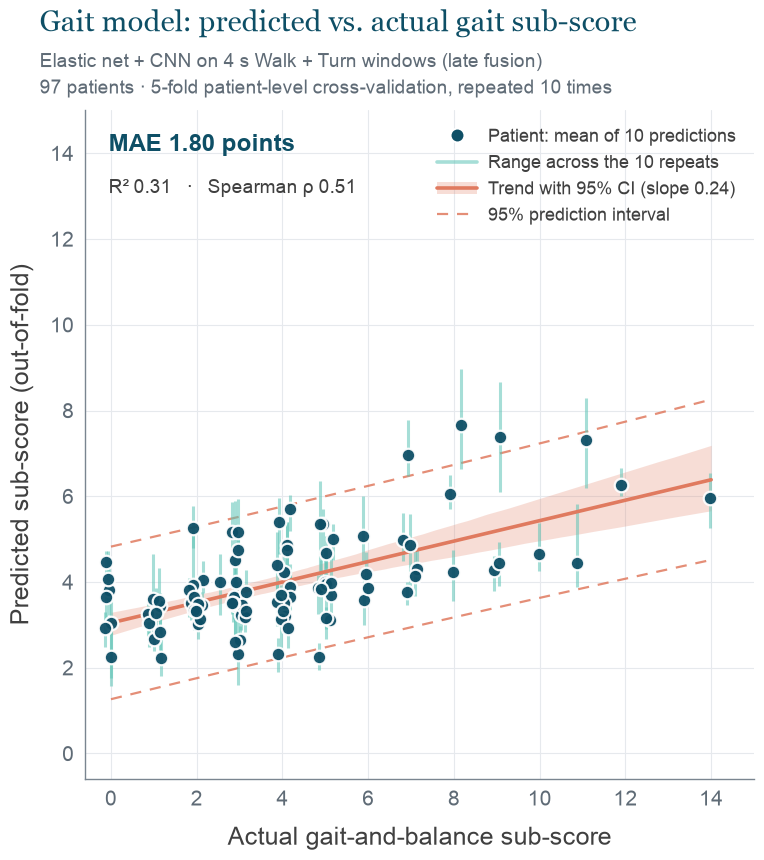

trend: predicted = 3.05 + 0.24 x actual (slope 95% CI 0.17 to 0.31; perfect prediction has slope 1); 95% prediction interval about ±1.8 points


In [11]:
from matplotlib.lines import Line2D
from matplotlib.patches import Patch
from scipy import stats


def predicted_vs_actual_figure(oof, summary, title=True, jitter=0.18, lim=(-0.6, 15.0), n_boot=1000):
    """Gait model predicted vs actual in the deck style: patient means, their range over the 10 repeats,
    the least-squares trend with its 95% confidence band (bootstrap over patients) and the 95% prediction interval."""
    D = deck_style
    pp = oof.groupby("patient").agg(actual=("y", "first"), predicted=("pred", "mean"),
                                    low=("pred", "min"), high=("pred", "max"))
    xa, yp = pp["actual"].to_numpy(), pp["predicted"].to_numpy()
    rng = np.random.default_rng(paths.SEED)
    xj = xa + rng.uniform(-jitter, jitter, len(pp))

    # trend: least-squares line of mean prediction on actual; 95% CI by resampling patients
    grid = np.linspace(xa.min(), xa.max(), 200)
    slope, icept = np.polyfit(xa, yp, 1)
    boot_lines, boot_slopes = [], []
    for _ in range(n_boot):
        i = rng.integers(0, len(xa), len(xa))
        b1, b0 = np.polyfit(xa[i], yp[i], 1)
        boot_lines.append(b0 + b1 * grid); boot_slopes.append(b1)
    band_lo, band_hi = np.percentile(boot_lines, [2.5, 97.5], axis=0)
    s_lo, s_hi = np.percentile(boot_slopes, [2.5, 97.5])
    # 95% prediction interval for one patient (ordinary least squares, t distribution)
    n = len(xa)
    resid_sd = np.sqrt(np.sum((yp - (icept + slope * xa)) ** 2) / (n - 2))
    pi_half = stats.t.ppf(0.975, n - 2) * resid_sd * np.sqrt(1 + 1 / n + (grid - xa.mean()) ** 2 / np.sum((xa - xa.mean()) ** 2))
    est, lo, hi = summary["estimate"], summary["ci_low"], summary["ci_high"]

    fig, ax = plt.subplots(figsize=(8.0, 8.8 if title else 8.0))
    ticks = np.arange(0, 15, 2)
    ax.set_xticks(ticks); ax.set_yticks(ticks)

    fit = icept + slope * grid
    for side in (-1, 1):   # 95% prediction interval
        ax.plot(grid, fit + side * pi_half, color=D.CORAL, linestyle=(0, (5, 4)), linewidth=1.6, alpha=0.85, zorder=2)
    ax.fill_between(grid, band_lo, band_hi, color=D.CORAL, alpha=0.25, linewidth=0, zorder=2)
    ax.plot(grid, fit, color=D.CORAL, linewidth=2.6, zorder=4)

    ax.vlines(xj, pp["low"], pp["high"], color=D.TEAL, alpha=0.55, linewidth=2.2, zorder=3)
    ax.scatter(xj, yp, s=95, color=D.DARK_TEAL, edgecolor=D.WHITE, linewidth=1.6, alpha=0.95, zorder=5)

    ax.set_xlim(*lim); ax.set_ylim(*lim)
    ax.set_aspect("equal")
    ax.set_xlabel("Actual gait-and-balance sub-score")
    ax.set_ylabel("Predicted sub-score (out-of-fold)")

    ax.text(0.035, 0.965, f"MAE {est['MAE']:.2f} points", transform=ax.transAxes, va="top", ha="left",
            fontsize=17, fontweight="bold", color=D.DARK_TEAL)
    ax.text(0.035, 0.905, f"R² {est['R2']:.2f}   ·   Spearman ρ {est['Spearman']:.2f}",
            transform=ax.transAxes, va="top", ha="left", fontsize=13.5, color=D.TEXT, linespacing=1.6)

    key = [Line2D([], [], marker="o", linestyle="none", markersize=10, markerfacecolor=D.DARK_TEAL,
                  markeredgecolor=D.WHITE, markeredgewidth=1.4, label="Patient: mean of 10 predictions"),
           Line2D([], [], color=D.TEAL, alpha=0.55, linewidth=2.6, label="Range across the 10 repeats"),
           (Patch(facecolor=D.CORAL, alpha=0.25, linewidth=0), Line2D([], [], color=D.CORAL, linewidth=2.6)),
           Line2D([], [], color=D.CORAL, linestyle=(0, (5, 4)), linewidth=1.6, alpha=0.85)]
    labels = ["Patient: mean of 10 predictions", "Range across the 10 repeats",
              f"Trend with 95% CI (slope {slope:.2f})", "95% prediction interval"]
    ax.legend(key, labels, loc="upper right", handletextpad=0.6, borderaxespad=0.6, handlelength=2.2)

    if title:
        D.title_block(fig, "Gait model: predicted vs. actual gait sub-score",
                      f"Elastic net + CNN on 4 s Walk + Turn windows (late fusion)\n"
                      f"{len(pp)} patients · 5-fold patient-level cross-validation, repeated 10 times")
        fig.subplots_adjust(left=0.13, right=0.97, bottom=0.09, top=0.85)
    else:
        fig.subplots_adjust(left=0.13, right=0.97, bottom=0.10, top=0.98)
    return fig, {"slope": slope, "slope_ci": (s_lo, s_hi), "intercept": icept, "pi_half_mean": pi_half.mean()}


with deck_style.context():
    fig, trend = predicted_vs_actual_figure(oof_gait, summary_gait, title=True)
    deck_style.save(fig, 'gc_predicted_vs_actual')
    slide, _ = predicted_vs_actual_figure(oof_gait, summary_gait, title=False)   # no title: the slide carries it
    deck_style.save(slide, 'gc_predicted_vs_actual_slide')
    plt.close(slide)
    plt.show()
print(f"trend: predicted = {trend['intercept']:.2f} + {trend['slope']:.2f} x actual "
      f"(slope 95% CI {trend['slope_ci'][0]:.2f} to {trend['slope_ci'][1]:.2f}; perfect prediction has slope 1); "
      f"95% prediction interval about ±{trend['pi_half_mean']:.1f} points")

## 8. Where the errors fall

Patients split into thirds by their actual sub-score; bias = predicted minus actual (negative = predicts too low).

In [12]:
by_range = evaluate.error_by_range(oof_gait).rename(columns={'actual Part III': 'actual sub-score'})
by_range.index = by_range.index.set_names('sub-score range')
by_range.to_csv(paths.TABLES_DIR / 'gc_error_by_range.csv')
by_range.round(2)

,patients,actual sub-score,MAE,bias
sub-score range,,,,
low,29,0 to 2,2.23,2.23
middle,34,3 to 4,0.81,0.31
high,34,5 to 14,2.41,-2.33


## 9. Clinic decision: who should come in?

The clinic needs a yes/no answer, so the Gait model's predicted sub-score is turned into a decision with one cut-off:

- **`gait_threshold = 3.75`**: a patient whose predicted sub-score is **above 3.75 is asked to come to the clinic**; otherwise not.
- **Needs the clinic** (the label the rule is judged against): **actual sub-score ≥ 4** (50 of the 97 patients).

**How 3.75 was chosen** (`scripts/choose_threshold.py`): AUROC does not depend on the cut-off, and missing nobody
means asking everyone in, so the cut-off balances the two errors. In each of the 50 splits the cut-off that maximises
sensitivity + specificity (Youden) was chosen on the other folds' predictions and applied to the held-out patients; the
chosen values had median 3.77 (range 3.61 to 4.20), the same as minimising missed + unneeded visits. **That honest estimate:
sensitivity 68% (95% CI 57% to 79%), specificity 69% (59% to 79%), about 16 of the 50 patients who need the clinic missed
and 14 unneeded visits per repeat.** The tables below apply 3.75 to the same predictions it was chosen from, so they are
slightly optimistic; quote the honest estimate. For comparison, a cut-off of 4.0 misses about 21 and asks 10 unneeded.

No separate classifier is trained: the rule reuses the Gait model's out-of-fold predictions, so every decision is for a patient the
models never saw.
Each metric is computed in each of the 10 repeats (every patient predicted once per repeat) and averaged, with a 95%
interval from resampling patients (1,000 bootstrap draws). AUROC measures how well the predicted score ranks patients who
need the clinic above those who do not, at any cut-off.

In [13]:
gait_threshold = 3.75   # predicted sub-score above which a patient is asked to come to the clinic
NEEDS_CLINIC_AT = 4     # clinical definition: actual sub-score >= 4 means the patient needs the clinic


def decision_metrics(y, pred, threshold=gait_threshold, needs_at=NEEDS_CLINIC_AT):
    """Screening metrics of the rule `pred > threshold` against the label `y >= needs_at`, for one repeat."""
    need, flag = y >= needs_at, pred > threshold
    tp, fn = (flag & need).sum(), (~flag & need).sum()
    fp, tn = (flag & ~need).sum(), (~flag & ~need).sum()
    return {"Sensitivity": tp / (tp + fn), "Specificity": tn / (tn + fp),
            "PPV": tp / (tp + fp) if tp + fp else np.nan, "NPV": tn / (tn + fn) if tn + fn else np.nan,
            "Accuracy": (tp + tn) / len(y), "Patients flagged": flag.sum(),
            "AUROC": evaluate._auroc(need, pred)}


def decision_summary(oof, n_boot=1000, seed=paths.SEED, **kw):
    """Metrics averaged over the 10 repeats, with a 95% CI from resampling patients (as evaluate.summarise)."""
    Y = oof.pivot(index="patient", columns="repeat", values="y")
    P = oof.pivot(index="patient", columns="repeat", values="pred").loc[Y.index]
    Y, P = Y.to_numpy(), P.to_numpy()
    avg = lambda idx: pd.DataFrame([decision_metrics(Y[idx, r], P[idx, r], **kw) for r in range(Y.shape[1])]).mean()
    est = avg(np.arange(len(Y)))
    rng = np.random.default_rng(seed)
    boot = pd.DataFrame([avg(rng.integers(0, len(Y), len(Y))) for _ in range(n_boot)])
    return pd.DataFrame({"estimate": est, "ci_low": boot.quantile(0.025), "ci_high": boot.quantile(0.975)})


decision = decision_summary(oof_gait)
need = oof_gait.drop_duplicates("patient")["y"] >= NEEDS_CLINIC_AT
print(f"gait_threshold = {gait_threshold}: flag when predicted sub-score > {gait_threshold}; "
      f"needs the clinic = actual sub-score >= {NEEDS_CLINIC_AT} ({need.sum()} of {len(need)} patients)")
decision.to_csv(paths.TABLES_DIR / "gc_decision.csv")
decision.round(2)

gait_threshold = 3.75: flag when predicted sub-score > 3.75; needs the clinic = actual sub-score >= 4 (50 of 97 patients)


,estimate,ci_low,ci_high
Sensitivity,0.71,0.60,0.82
Specificity,0.70,0.60,0.80
PPV,0.71,0.60,0.82
NPV,0.69,0.57,0.80
Accuracy,0.70,0.63,0.78
Patients flagged,49.80,41.40,58.00
AUROC,0.74,0.64,0.83


In [14]:
flags = oof_gait.assign(need=oof_gait["y"] >= NEEDS_CLINIC_AT, flag=oof_gait["pred"] > gait_threshold)
confusion = (flags.groupby(["repeat", "need", "flag"]).size().unstack(["need", "flag"], fill_value=0).mean()
             .unstack("flag").reindex(index=[True, False], columns=[True, False]))
confusion.index = ["Needs clinic (actual ≥ 4)", "Does not (actual < 4)"]
confusion.columns = ["Asked to come (pred > threshold)", "Not asked"]
confusion["Total"] = confusion.sum(axis=1)
confusion.to_csv(paths.TABLES_DIR / "gc_decision_confusion.csv")
print("Patients per repeat, averaged over the 10 repeats (97 patients each):")
confusion.round(1)

Patients per repeat, averaged over the 10 repeats (97 patients each):


,Asked to come (pred > threshold),Not asked,Total
Needs clinic (actual ≥ 4),35.5,14.5,50.0
Does not (actual < 4),14.3,32.7,47.0


**Consistency.** Each patient is predicted once in each of the 10 repeats; how often is the same patient asked to come?

In [15]:
times = flags.groupby("patient").agg(need=("need", "first"), flagged=("flag", "sum"))
consistency = (pd.cut(times["flagged"], [-1, 0, 9, 10], labels=["Never (0 of 10)", "Sometimes (1-9 of 10)", "Always (10 of 10)"])
               .groupby(times["need"].map({True: "Needs clinic", False: "Does not"})).value_counts()
               .unstack(0).reindex(columns=["Needs clinic", "Does not"]))
consistency.index.name = "Asked to come, across the 10 repeats"
consistency.to_csv(paths.TABLES_DIR / "gc_decision_consistency.csv")
consistency

need,Needs clinic,Does not
"Asked to come, across the 10 repeats",,
Never (0 of 10),8,19
Sometimes (1-9 of 10),18,23
Always (10 of 10),24,5


Shaded areas: the four outcomes of the rule. Points are each patient's mean prediction over the 10 repeats (spread
horizontally by up to ±0.18 so tied scores stay visible), so the patient counts can differ slightly from the per-repeat
averages in the tables; the metrics on the right are the per-repeat averages.

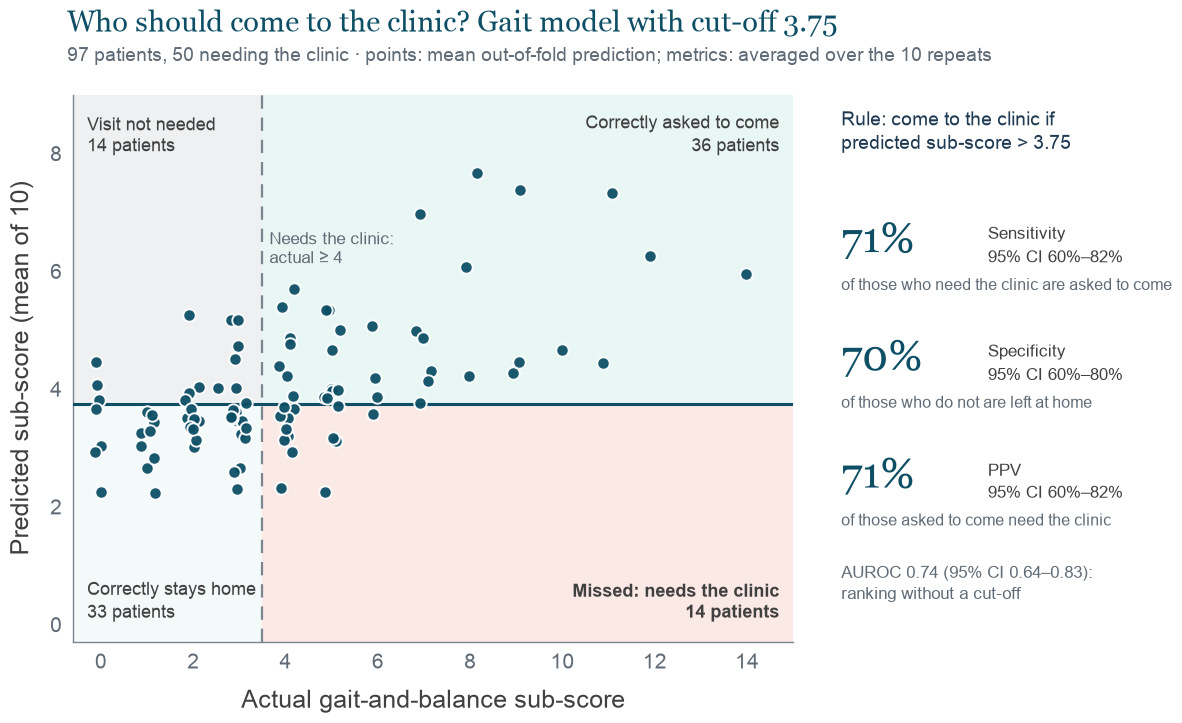

In [16]:
def decision_figure(oof, decision, threshold=gait_threshold, needs_at=NEEDS_CLINIC_AT, title=True,
                    jitter=0.18, xlim=(-0.6, 15.0), ylim=(-0.3, 9.0)):
    """Predicted vs actual split into the four outcomes of the clinic rule, with the screening metrics beside it."""
    D = deck_style
    pp = oof.groupby("patient").agg(actual=("y", "first"), predicted=("pred", "mean"))
    xa, yp = pp["actual"].to_numpy(), pp["predicted"].to_numpy()
    xj = xa + np.random.default_rng(paths.SEED).uniform(-jitter, jitter, len(pp))
    xb = needs_at - 0.5                         # actual scores are whole points (one prorated 2.4): 3 | 4
    need, flag = xa >= needs_at, yp > threshold

    fig = plt.figure(figsize=(12.0, 7.4 if title else 6.9))
    ax = fig.add_axes([0.08, 0.11, 0.60, 0.74 if title else 0.83])
    side = fig.add_axes([0.72, 0.11, 0.26, 0.74 if title else 0.83]); side.axis("off")

    quads = [  # (x0, x1, y0, y1, colour, alpha, label, count, label position)
        (xb, xlim[1], threshold, ylim[1], D.TEAL, 0.14, "Correctly asked to come", (need & flag).sum(), (xlim[1] - 0.3, ylim[1] - 0.3, "right", "top")),
        (xb, xlim[1], ylim[0], threshold, D.CORAL, 0.16, "Missed: needs the clinic", (need & ~flag).sum(), (xlim[1] - 0.3, ylim[0] + 0.3, "right", "bottom")),
        (xlim[0], xb, threshold, ylim[1], D.GREY, 0.12, "Visit not needed", (~need & flag).sum(), (xlim[0] + 0.3, ylim[1] - 0.3, "left", "top")),
        (xlim[0], xb, ylim[0], threshold, D.TEAL, 0.07, "Correctly stays home", (~need & ~flag).sum(), (xlim[0] + 0.3, ylim[0] + 0.3, "left", "bottom")),
    ]
    for x0, x1, y0, y1, c, a, lab, n, (tx, ty, ha, va) in quads:
        ax.axvspan(x0, x1, ymin=(y0 - ylim[0]) / (ylim[1] - ylim[0]), ymax=(y1 - ylim[0]) / (ylim[1] - ylim[0]),
                   color=c, alpha=a, linewidth=0, zorder=0)
        ax.text(tx, ty, f"{lab}\n{n} patients", ha=ha, va=va, fontsize=13, color=D.TEXT, linespacing=1.35, zorder=6,
                fontweight="bold" if lab.startswith("Missed") else "normal")

    ax.axhline(threshold, color=D.DARK_TEAL, linewidth=2.2, zorder=4)
    ax.axvline(xb, color=D.GREY, linestyle=(0, (6, 4)), linewidth=1.6, zorder=4)
    ax.text(xb + 0.15, (threshold + ylim[1]) / 2, f"Needs the clinic:\nactual ≥ {needs_at}", ha="left", va="center",
            fontsize=12.5, color=D.TEXT_2, zorder=6)

    ax.scatter(xj, yp, s=80, color=D.DARK_TEAL, edgecolor=D.WHITE, linewidth=1.4, alpha=0.95, zorder=5)
    ax.set_xlim(*xlim); ax.set_ylim(*ylim)
    ax.set_xticks(np.arange(0, 15, 2)); ax.set_yticks(np.arange(0, 10, 2))
    ax.set_xlabel("Actual gait-and-balance sub-score")
    ax.set_ylabel("Predicted sub-score (mean of 10)")
    ax.grid(False)

    est, lo, hi = decision["estimate"], decision["ci_low"], decision["ci_high"]
    rows = [("Sensitivity", "of those who need the clinic are asked to come"),
            ("Specificity", "of those who do not are left at home"),
            ("PPV", "of those asked to come need the clinic")]
    y0 = 0.98
    side.text(0, y0, "Rule: come to the clinic if\npredicted sub-score > " + f"{threshold:g}",
              fontsize=14, color=D.NAVY, va="top", linespacing=1.4, transform=side.transAxes)
    y0 -= 0.21
    for k, desc in rows:
        side.text(0, y0, f"{est[k]:.0%}", fontsize=30, color=D.DARK_TEAL, va="top", family="serif",
                  transform=side.transAxes)
        side.text(0.47, y0 - 0.005, f"{k}\n95% CI {lo[k]:.0%}–{hi[k]:.0%}", fontsize=12.5, color=D.TEXT, va="top",
                  linespacing=1.35, transform=side.transAxes)
        side.text(0, y0 - 0.105, desc, fontsize=11.5, color=D.TEXT_2, va="top", transform=side.transAxes)
        y0 -= 0.215
    side.text(0, y0 + 0.02, f"AUROC {est['AUROC']:.2f} (95% CI {lo['AUROC']:.2f}–{hi['AUROC']:.2f}):\nranking without a cut-off",
              fontsize=12, color=D.TEXT_2, va="top", linespacing=1.35, transform=side.transAxes)

    if title:
        D.title_block(fig, f"Who should come to the clinic? Gait model with cut-off {threshold:g}",
                      f"{len(pp)} patients, {need.sum()} needing the clinic · points: mean out-of-fold prediction; "
                      "metrics: averaged over the 10 repeats")
    return fig


with deck_style.context():
    fig = decision_figure(oof_gait, decision, title=True)
    deck_style.save(fig, "gc_decision")
    slide = decision_figure(oof_gait, decision, title=False)
    deck_style.save(slide, "gc_decision_slide")
    plt.close(slide)
    plt.show()

## 10. What the model is worth: specialist time for the patients who need it

**The idea in one line:** patients do the short home walk before each 6-monthly review; if the Gait model predicts a gait
sub-score of 3.75 or less, the clinic review is deferred, and the specialist time it frees is used for patients who truly
need care.

**The story, for one year at Edge Movement Clinic** (fictional; 1,500 patients, a 2-hour review every 6 months):

1. **Today:** 3,000 reviews take 6,000 specialist hours, and about half of them go to patients whose gait is stable.
2. **With the model:** every review where the home walk looks stable is deferred and replaced by a short remote check.
3. **Freed time:** the hours saved are used for patients who need care, as extra 2-hour appointments.
4. **The point:** the share of specialist time spent on patients who need care rises sharply.
5. **The money:** the freed time valued at \$500 per specialist hour, plus visit costs avoided, minus the home walks and
   catch-up visits for patients the model missed.
6. **The trade-off:** some deferred patients did need care (actual sub-score ≥ 4); they wait for their next review
   6 months later unless they come back sooner (counted as catch-up visits).

How often a review is deferred, and how often that patient needed care, come from the Gait model's out-of-fold decisions in
Section 9. The clinic and money figures are **planning assumptions** in US dollars (below); change them in one place.

In [17]:
# ---- planning assumptions (fictional clinic; change them here) -------------------------------------------------
PATIENTS = 1500               # patients under follow-up, each reviewed every 6 months
REVIEW_MIN = 120              # length of a clinic review (minutes): 2 hours
REMOTE_CHECK_MIN = 5          # clinician time to check a deferred patient's home walk (minutes)
SPECIALIST_COST_HOUR = 500    # $ per specialist hour (fully loaded): the value of each freed hour
VISIT_OVERHEAD = 50           # $ non-staff cost of a clinic visit (room, admin, consumables)
HOME_WALK_COST = 15           # $ per home walk (sensor kit, postage, data)
CATCHUP_SHARE = 0.5           # share of missed patients who come back for an unplanned visit
CATCHUP_COST = 310            # $ per unplanned visit

# ---- what the Gait model does at gait_threshold (Section 9), as shares of reviews --------------------------------------
share_deferred = (~flags["flag"]).mean()                        # walk looks stable: review deferred
share_missed = (~flags["flag"] & flags["need"]).mean()          # deferred although the actual sub-score is >= 4
share_need = flags["need"].mean()                               # patients who need care (actual sub-score >= 4)
share_kept_need = (flags["flag"] & flags["need"]).mean()        # reviews kept for patients who need care

# ---- one year --------------------------------------------------------------------------------------------------
reviews = PATIENTS * 2
review_h = REVIEW_MIN / 60
deferred = reviews * share_deferred
missed = reviews * share_missed
check_h = deferred * REMOTE_CHECK_MIN / 60
hours_freed = deferred * review_h - check_h
extra_appointments = hours_freed / review_h                     # extra 2-hour appointments for patients who need care

# where the specialist hours go, today and with the model
hours = pd.DataFrame({
    "Today": {"Patients who need care": reviews * share_need * review_h,
              "Patients whose gait is stable": reviews * (1 - share_need) * review_h,
              "Remote checks of home walks": 0.0,
              "Freed time, given to patients who need care": 0.0},
    "With the home walk (Gait model)": {"Patients who need care": reviews * share_kept_need * review_h,
                           "Patients whose gait is stable": reviews * (1 - share_deferred - share_kept_need) * review_h,
                           "Remote checks of home walks": check_h,
                           "Freed time, given to patients who need care": hours_freed},
})
need_share_today = hours.loc["Patients who need care", "Today"] / hours["Today"].sum()
need_share_model = (hours.loc[["Patients who need care", "Freed time, given to patients who need care"],
                              "With the home walk (Gait model)"].sum() / hours["With the home walk (Gait model)"].sum())

money = pd.Series({
    "Freed specialist time": hours_freed * SPECIALIST_COST_HOUR,
    "Visit costs avoided": deferred * VISIT_OVERHEAD,
    "Home walks": -reviews * HOME_WALK_COST,
    "Catch-up visits for missed patients": -missed * CATCHUP_SHARE * CATCHUP_COST,
}, name="$ per year")
money["Net value to the clinic"] = money.sum()

story = pd.DataFrame([
    ("Today", "clinic reviews a year", reviews),
    ("Today", "specialist hours a year", reviews * review_h),
    ("With the model", "reviews deferred (walk looks stable)", deferred),
    ("Freed time", "specialist hours freed", hours_freed),
    ("Freed time", f"value of that time at ${SPECIALIST_COST_HOUR}/h ($)", hours_freed * SPECIALIST_COST_HOUR),
    ("Patients helped", "extra 2-hour appointments for patients who need care", extra_appointments),
    ("The point", "share of specialist time on patients who need care, today (%)", 100 * need_share_today),
    ("The point", "share of specialist time on patients who need care, with the model (%)", 100 * need_share_model),
    ("The money", "net value to the clinic ($)", money["Net value to the clinic"]),
    ("The trade-off", "deferred reviews where the patient needed care", missed),
], columns=["step", "per year", "value"]).set_index(["step", "per year"])
story.to_csv(paths.TABLES_DIR / "gc_impact.csv")
money.to_csv(paths.TABLES_DIR / "gc_impact_money.csv")
hours.to_csv(paths.TABLES_DIR / "gc_impact_hours.csv")
print(f"At gait_threshold = {gait_threshold}, the model defers {share_deferred:.0%} of reviews; "
      f"{share_missed / share_deferred:.0%} of deferred reviews are for patients who needed care.")
display(story.round(0).astype(int).style.format("{:,}"))
display(money.round(0).astype(int).to_frame().style.format("{:,}"))
hours.round(0).astype(int).style.format("{:,}")

At gait_threshold = 3.75, the model defers 49% of reviews; 31% of deferred reviews are for patients who needed care.


,$ per year
Freed specialist time,"1,398,969"
Visit costs avoided,"72,990"
Home walks,"-45,000"
Catch-up visits for missed patients,"-69,510"
Net value to the clinic,"1,357,448"


,Today,With the home walk (Gait model)
Patients who need care,"3,093","2,196"
Patients whose gait is stable,"2,907",885
Remote checks of home walks,0,122
"Freed time, given to patients who need care",0,"2,798"


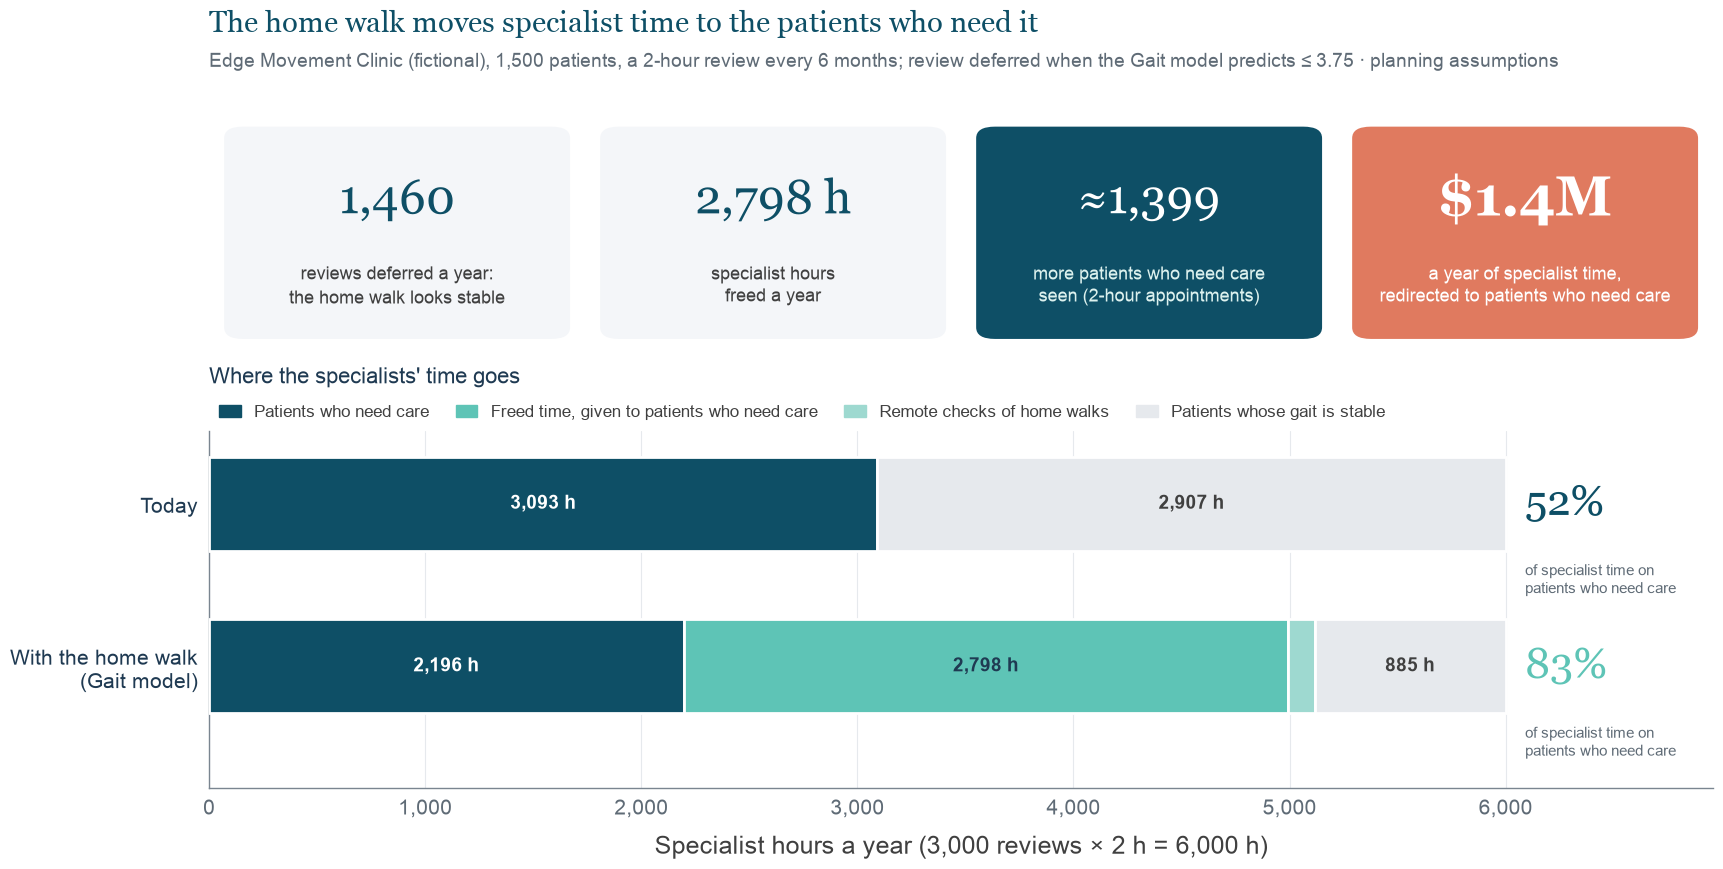

In [18]:
from matplotlib.patches import FancyBboxPatch, Patch


def impact_figure(title=True):
    """Where the specialists' hours go, today and with the home walk, under four headline numbers ending on their value."""
    D = deck_style
    fig = plt.figure(figsize=(16, 8.6 if title else 7.8))
    gs = fig.add_gridspec(2, 1, height_ratios=[1.0, 1.55], hspace=0.28,
                          left=0.03, right=0.97, bottom=0.08, top=0.86 if title else 0.97)

    # ---- headline cards --------------------------------------------------------------------------------------
    top = fig.add_subplot(gs[0]); top.axis("off"); top.set_xlim(0, 4); top.set_ylim(0, 1)
    cards = [(f"{deferred:,.0f}", "reviews deferred a year:\nthe home walk looks stable", D.CARD, D.DARK_TEAL, D.TEXT, "none"),
             (f"{hours_freed:,.0f} h", "specialist hours\nfreed a year", D.CARD, D.DARK_TEAL, D.TEXT, "none"),
             (f"≈{extra_appointments:,.0f}", f"more patients who need care\nseen ({REVIEW_MIN / 60:g}-hour appointments)",
              D.DARK_TEAL, D.WHITE, D.MINT, "none"),
             (f"${hours_freed * SPECIALIST_COST_HOUR / 1e6:,.1f}M", "a year of specialist time,\nredirected to patients who need care",
              D.CORAL, D.WHITE, D.WHITE, "none")]
    for j, (big, small, fc, tc, sc, ec) in enumerate(cards):
        top.add_patch(FancyBboxPatch((j + 0.04, 0.04), 0.92, 0.92, boxstyle="round,pad=0,rounding_size=0.05",
                                     fc=fc, ec=ec, lw=2.2))
        top.text(j + 0.5, 0.64, big, ha="center", va="center", fontsize=40 if j == 3 else 34, color=tc, family="serif",
                 fontweight="bold" if j == 3 else "normal")
        top.text(j + 0.5, 0.27, small, ha="center", va="center", fontsize=13, color=sc, linespacing=1.3)

    # ---- where the specialist hours go ----------------------------------------------------------------------
    ax = fig.add_subplot(gs[1])
    segs = [("Patients who need care", D.DARK_TEAL, D.WHITE),
            ("Freed time, given to patients who need care", D.TEAL, D.NAVY),
            ("Remote checks of home walks", D.LIGHT_TEAL, D.NAVY),
            ("Patients whose gait is stable", D.GRID, D.TEXT)]
    rows = ["With the home walk (Gait model)", "Today"]
    total = hours["Today"].sum()
    for r, col in enumerate(rows):
        left = 0
        for name, colour, tcol in segs:
            v = hours.loc[name, col]
            if v <= 0:
                continue
            ax.barh(r, v, left=left, color=colour, height=0.58, edgecolor=D.WHITE, linewidth=2, zorder=3)
            if v / total > 0.07:
                ax.text(left + v / 2, r, f"{v:,.0f} h", ha="center", va="center", fontsize=14, color=tcol,
                        fontweight="bold", zorder=4)
            left += v
    share = {"Today": need_share_today, "With the home walk (Gait model)": need_share_model}
    for r, col in enumerate(rows):
        ax.text(total * 1.015, r, f"{share[col]:.0%}", ha="left", va="center", fontsize=30, family="serif",
                color=D.DARK_TEAL if col == "Today" else D.TEAL)
        ax.text(total * 1.015, r - 0.36, "of specialist time on\npatients who need care", ha="left", va="top",
                fontsize=11, color=D.TEXT_2, linespacing=1.25)
    ax.set_yticks(range(len(rows)))
    ax.set_yticklabels([r.replace(" (", "\n(") for r in rows], fontsize=15, color=D.NAVY, linespacing=1.3)
    ax.set_xlim(0, total * 1.16); ax.set_ylim(-0.75, 1.45)
    ax.set_xlabel(f"Specialist hours a year ({reviews:,} reviews × {REVIEW_MIN / 60:g} h = {total:,.0f} h)")
    ax.set_title("Where the specialists' time goes", loc="left", fontsize=16, color=D.NAVY, pad=34)
    ax.grid(axis="y", visible=False)
    ax.legend(handles=[Patch(color=c, label=n) for n, c, _ in segs], loc="lower left", bbox_to_anchor=(0, 1.0),
              ncol=4, fontsize=12, handlelength=1.3, columnspacing=1.6, borderaxespad=0.2)
    ax.xaxis.set_major_formatter(plt.FuncFormatter(lambda v, _: f"{v:,.0f}"))
    if title:
        D.title_block(fig, "The home walk moves specialist time to the patients who need it",
                      f"Edge Movement Clinic (fictional), {PATIENTS:,} patients, a {REVIEW_MIN / 60:g}-hour review every "
                      f"6 months; review deferred when the Gait model predicts ≤ {gait_threshold:g} · planning assumptions",
                      x=0.03, top=0.985)
    return fig


with deck_style.context():
    fig = impact_figure(title=True)
    deck_style.save(fig, "gc_impact")
    slide = impact_figure(title=False)
    deck_style.save(slide, "gc_impact_slide")
    plt.close(slide)
    plt.show()

## 11. Summary

Results of the run on 2026-11-23 (50 splits; the numbers above recompute from the cache).

| Metric | Gait model (95% interval) |
|---|---|
| MAE | **1.80 points** (1.54 to 2.09) |
| RMSE | 2.34 (1.94 to 2.75) |
| R² | 0.31 (0.18 to 0.40) |
| Spearman | 0.51 (0.37 to 0.64) |

- **Typical error: 1.80 points** on a 0-24 scale whose actual values in this cohort run from 0 to 14 (median 4).
- **Accurate in the middle, compressed at the ends** (Section 8): MAE 0.81 for patients scoring 3-4, but 2.23 for those
  scoring 0-2 (predicted too high by 2.2 on average) and 2.41 for those scoring 5-14 (predicted too low by 2.3). The model
  pulls predictions towards the typical score: no patient's average prediction exceeds 8, although 8 patients score above 8.
- **The trend of predictions on actual scores has slope 0.24** (95% CI 0.17 to 0.31; perfect prediction = 1): for each
  extra point of actual impairment the prediction rises by about a quarter of a point.
- **It ranks patients better than it estimates their score** (Spearman 0.51). For flagging the most impaired patients, a
  cut-off on the prediction well below the clinical threshold works better than the predicted score itself.
- **Clinic decision** (Section 9): asked to come when the predicted sub-score is above `gait_threshold = 3.75`; "needs
  the clinic" = actual ≥ 4 (50 of 97). 3.75 balances missed patients against unneeded visits (chosen inside the splits:
  median 3.77). **Honest estimate (cut-off chosen inside each split): sensitivity 68% (95% CI 57% to 79%), specificity 69%
  (59% to 79%)**, about 16 missed and 14 unneeded visits per repeat. Applying 3.75 to all predictions (slightly optimistic):
  sensitivity 71%, specificity 70%, PPV 71%, about 50 of 97 asked to come; AUROC 0.74 (0.64 to 0.83) at any cut-off. The 14
  patients missed on their mean prediction all score 4-6 (9 of them exactly 4): the compression in Section 8. A cut-off of
  4.0 would miss about 21.
- **What it is worth** (Section 10; fictional clinic of 1,500 patients, a 2-hour review every 6 months, planning
  assumptions in US dollars): deferring every review where the home walk predicts ≤ 3.75 defers about **1,460 of 3,000
  reviews a year** and frees about **2,800 specialist hours** (about \$1.4M at \$500 an hour), enough for about **1,400
  more 2-hour appointments for patients who need care**. The share of specialist time spent on patients who need care
  rises from **52% to 83%**; net value to the clinic is about **\$1.36M a year**. The trade-off: about **450 deferred
  reviews a year are for patients who needed care**.
- **Inputs**: structured clinical data plus unstructured sensor recordings, used twice: as 210 engineered gait and tremor
  features in the elastic net (early fusion) and as raw 4 s Walk + Turn windows in the CNN; the two predictions are averaged
  (late fusion).

Outputs: `results/tables/gc_*.csv` (windows, results, error by range, decision, confusion, consistency, impact, impact money, impact hours) and `results/figures/gc_*` (window example,
predicted against actual, the CNN architecture (diagram and block view), the clinic decision and its impact, each with and without title, as PNG 600 dpi, PDF and SVG, in the deck's theme).